# Penerapan Machine Learning untuk Klasifikasi Risiko Diabetes Menggunakan Algoritma Random Forest

1. Permasalahan yang dihadapi
Diabetes merupakan salah satu masalah kesehatan yang perlu mendapatkan perhatian karena berkaitan dengan kadar glukosa dalam darah. Data kesehatan dapat dimanfaatkan untuk mempelajari pola yang membedakan individu dengan label diabetes dan individu tanpa label diabetes.
Permasalahan yang dibahas dalam penelitian ini adalah bagaimana menerapkan algoritma Machine Learning untuk mengklasifikasikan data berdasarkan sejumlah variabel kesehatan. Pengklasifikasian dilakukan menggunakan algoritma Random Forest dengan memanfaatkan data historis yang telah memiliki label kelas.
Model yang dihasilkan diharapkan dapat mempelajari hubungan antara variabel masukan dan label diabetes pada dataset. Hasil klasifikasi digunakan untuk mengevaluasi kemampuan algoritma dalam membedakan kedua kelas tersebut.

2. Metode klasifikasi yang digunakan
Metode yang digunakan adalah Random Forest, yaitu algoritma Machine Learning yang menggabungkan banyak pohon keputusan (decision trees) untuk menghasilkan prediksi. Random Forest membangun sejumlah pohon keputusan menggunakan sampel data dan pemilihan fitur yang bervariasi. Untuk klasifikasi, hasil prediksi dari pohon-pohon tersebut digabungkan melalui mekanisme pemungutan suara mayoritas. Metode ini dipilih karena mampu menangani hubungan yang tidak selalu linear antarvariabel, dapat digunakan untuk klasifikasi dua kelas, dan menyediakan informasi mengenai tingkat kepentingan fitur.

3. Dataset yang digunakan
Dataset yang digunakan adalah Pima Indians Diabetes Database yang diperoleh melalui Kaggle.
Sumber : Pima Indians Diabetes Database – Kaggle.
Dataset terdiri dari 768 baris data, 8 variabel masukan, dan 1 variabel target. Dataset ini secara historis berisi data perempuan dari populasi Pima Indian, sehingga karakteristik datanya tidak dapat langsung dianggap mewakili seluruh populasi.
Variabel yang digunakan adalah sebagai berikut.
Jumlah kehamilan, Kadar glukosa, Tekanan darah, Ketebalan lipatan kulit, Kadar insulin, Indeks massa tubuh, Indikator riwayat diabetes keluarga, Usia. Outcome	Label target: 0 = tidak diabetes, 1 = diabetes
Delapan variabel pertama digunakan sebagai fitur atau variabel masukan, sedangkan Outcome digunakan sebagai target yang akan diprediksi oleh model.

4. Manfaat
Manfaat kegiatan ini adalah memberikan pemahaman praktis tentang pemanfaatan algoritma klasifikasi untuk analisis data kesehatan, mulai dari pengolahan data hingga evaluasi model. Model ini hanya digunakan untuk pembelajaran dan penelitian, bukan sebagai alat diagnosis medis atau penentu pasti risiko diabetes seseorang.


Tahap awal memasukkan dataset

In [1]:
# Mengimpor library untuk membaca dan mengolah data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from io import BytesIO

# Mengunggah file CSV dari komputer
uploaded = files.upload()

# Membaca file CSV
nama_file = next(iter(uploaded))
df = pd.read_csv(BytesIO(uploaded[nama_file]), sep=';')

# Membersihkan nama kolom dari spasi yang tidak diperlukan
df.columns = df.columns.str.strip()

# Menampilkan lima baris pertama
df.head()

Saving diabetes _klasifikasi.csv to diabetes _klasifikasi.csv


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Tahap ini digunakan untuk memahami karakteristik awal dataset sebelum pemodelan dilakukan.

In [2]:
# Menampilkan ukuran dataset
print("Ukuran dataset:", df.shape)

# Menampilkan nama kolom
print("\nNama kolom:")
print(df.columns.tolist())

# Menampilkan informasi tipe data
print("\nInformasi dataset:")
df.info()

# Memeriksa nilai kosong
print("\nJumlah nilai kosong:")
print(df.isnull().sum())

# Melihat statistik deskriptif
print("\nStatistik deskriptif:")
display(df.describe())

Ukuran dataset: (768, 9)

Nama kolom:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Jumlah nilai kosong:
Pregnancies                 0
Gluco

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Tahap ini digunakan untuk mengetahui jumlah data pada masing-masing kelas.

Distribusi kelas Outcome:
Outcome
0    500
1    268
Name: count, dtype: int64

Persentase kelas (%):
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64


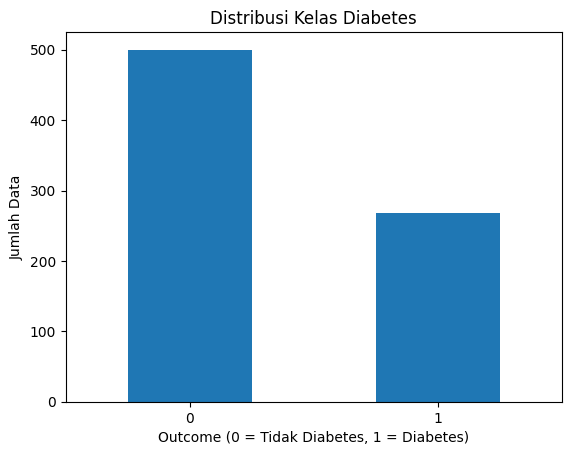

In [3]:
# Menghitung jumlah data setiap kelas
print("Distribusi kelas Outcome:")
print(df["Outcome"].value_counts().sort_index())

# Menampilkan persentase setiap kelas
print("\nPersentase kelas (%):")
print((df["Outcome"].value_counts(normalize=True)
       .sort_index() * 100).round(2))

# Membuat diagram batang distribusi kelas
df["Outcome"].value_counts().sort_index().plot(
    kind="bar",
    rot=0
)

plt.title("Distribusi Kelas Diabetes")
plt.xlabel("Outcome (0 = Tidak Diabetes, 1 = Diabetes)")
plt.ylabel("Jumlah Data")
plt.show()

Pada tahap ini digunakan untuk memeriksa dan memperbaiki data

In [4]:
# Memastikan seluruh kolom menggunakan tipe numerik
df = df.apply(pd.to_numeric, errors="coerce")

# Memeriksa nilai target yang valid
print("Nilai target yang ditemukan:")
print(sorted(df["Outcome"].dropna().unique()))

# Memeriksa data duplikat
print("\nJumlah baris duplikat:", df.duplicated().sum())

# Menghapus baris dengan target kosong atau di luar kelas 0 dan 1
df = df.dropna(subset=["Outcome"])
df = df[df["Outcome"].isin([0, 1])].copy()

# Menghapus duplikat jika ada
df = df.drop_duplicates().reset_index(drop=True)

# Mengubah nilai nol yang tidak valid menjadi NaN
kolom_nol_tidak_valid = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df[kolom_nol_tidak_valid] = df[kolom_nol_tidak_valid].replace(
    0, np.nan
)

# Memeriksa jumlah nilai yang perlu ditangani
print("\nJumlah nilai kosong setelah pemeriksaan:")
print(df.isnull().sum())

Nilai target yang ditemukan:
[np.int64(0), np.int64(1)]

Jumlah baris duplikat: 0

Jumlah nilai kosong setelah pemeriksaan:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


Memisahkan fitur dan target

In [5]:
# Menentukan fitur (X) dan target (y)
X = df.drop(columns=["Outcome"])
y = df["Outcome"].astype(int)

print("Jumlah fitur:", X.shape[1])
print("Nama fitur:", X.columns.tolist())
print("Jumlah target:", y.shape[0])

Jumlah fitur: 8
Nama fitur: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Jumlah target: 768


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Jumlah data latih:", X_train.shape[0])
print("Jumlah data uji:", X_test.shape[0])

print("\nDistribusi kelas data latih:")
print(y_train.value_counts().sort_index())

print("\nDistribusi kelas data uji:")
print(y_test.value_counts().sort_index())

Jumlah data latih: 614
Jumlah data uji: 154

Distribusi kelas data latih:
Outcome
0    400
1    214
Name: count, dtype: int64

Distribusi kelas data uji:
Outcome
0    100
1     54
Name: count, dtype: int64


Pada tahap ini, kita menggunakan SimpleImputer untuk mengisi nilai kosong dengan median dan RandomForestClassifier untuk membangun model klasifikasi.

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# Membuat pipeline prapemrosesan dan model
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("random_forest", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

# Melatih model menggunakan data latih
model.fit(X_train, y_train)

print("Model Random Forest berhasil dilatih.")

Model Random Forest berhasil dilatih.


Setelah pelatihan selesai, model diuji menggunakan data uji

=== HASIL EVALUASI RANDOM FOREST ===
Accuracy  : 0.7468 (74.68%)
Precision : 0.6596 (65.96%)
Recall    : 0.5741 (57.41%)
F1-score  : 0.6139 (61.39%)

Laporan klasifikasi:
                precision    recall  f1-score   support

Tidak Diabetes       0.79      0.84      0.81       100
      Diabetes       0.66      0.57      0.61        54

      accuracy                           0.75       154
     macro avg       0.72      0.71      0.71       154
  weighted avg       0.74      0.75      0.74       154



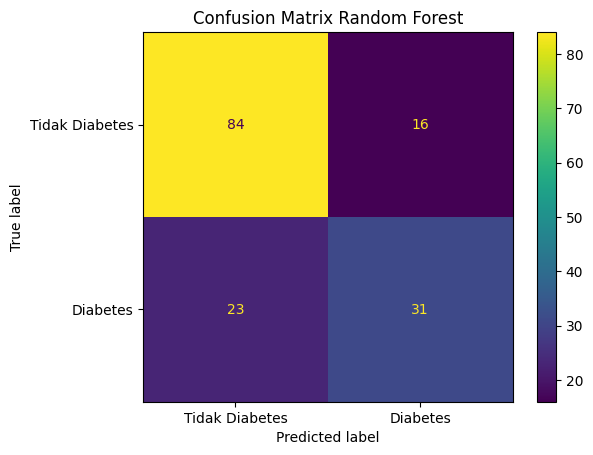

In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Melakukan prediksi pada data uji
y_pred = model.predict(X_test)

# Menghitung metrik evaluasi
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("=== HASIL EVALUASI RANDOM FOREST ===")
print(f"Accuracy  : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision : {precision:.4f} ({precision*100:.2f}%)")
print(f"Recall    : {recall:.4f} ({recall*100:.2f}%)")
print(f"F1-score  : {f1:.4f} ({f1*100:.2f}%)")

print("\nLaporan klasifikasi:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Tidak Diabetes", "Diabetes"],
    zero_division=0
))

# Menampilkan confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Tidak Diabetes", "Diabetes"]
)

disp.plot()
plt.title("Confusion Matrix Random Forest")
plt.show()

Random Forest menyediakan informasi feature importance untuk melihat fitur mana yang paling banyak berkontribusi terhadap keputusan model berdasarkan kriteria internal algoritma.

,Variabel,Feature Importance
1,Glucose,0.271711
5,BMI,0.170920
6,DiabetesPedigreeFunction,0.117682
7,Age,0.117371
4,Insulin,0.097319
2,BloodPressure,0.078509
0,Pregnancies,0.076375
3,SkinThickness,0.070114


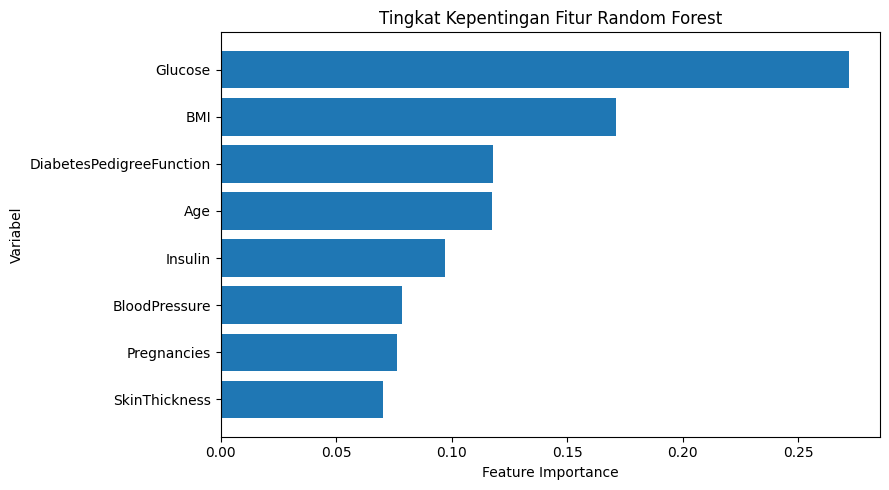

In [12]:
# Mengambil model Random Forest dari pipeline
rf = model.named_steps["random_forest"]

# Membuat tabel tingkat kepentingan fitur
importance = pd.DataFrame({
    "Variabel": X.columns,
    "Feature Importance": rf.feature_importances_
}).sort_values(
    by="Feature Importance",
    ascending=False
)
display(importance)

# Membuat grafik
plt.figure(figsize=(9, 5))
plt.barh(
    importance["Variabel"],
    importance["Feature Importance"]
)
plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.ylabel("Variabel")
plt.title("Tingkat Kepentingan Fitur Random Forest")
plt.tight_layout()
plt.show()

Penjelasan:
Hasil akan menampilkan urutan variabel berdasarkan nilai feature importance. Nilai yang lebih tinggi menunjukkan kontribusi yang lebih besar terhadap pembagian keputusan pohon-pohon dalam model.

### Kesimpulan

Berdasarkan pengolahan data menggunakan algoritma Random Forest pada Pima Indians Diabetes Database, model berhasil dilatih untuk mengklasifikasikan data ke dalam dua kelas, yaitu Tidak Diabetes dan Diabetes, berdasarkan variabel kesehatan dan label Outcome.
Berdasarkan hasil evaluasi pada data uji sebanyak 154 data, model memperoleh nilai accuracy sebesar 74,68%, precision sebesar 65,96%, recall sebesar 57,41%, dan F1-score sebesar 61,39%. Hasil tersebut menunjukkan bahwa model mampu mengklasifikasikan sekitar 74,68% dari seluruh data uji dengan benar. Pada kelas Tidak Diabetes, model memperoleh precision sebesar 79% dan recall sebesar 84%. Sementara itu, pada kelas Diabetes, model memperoleh precision sebesar 66% dan recall sebesar 57%. Hal ini menunjukkan bahwa model masih belum mampu mengenali seluruh data yang termasuk dalam kelas Diabetes secara optimal.
Hasil feature importance menunjukkan bahwa variabel Glucose memiliki tingkat kepentingan tertinggi dengan nilai sebesar 0,271711, diikuti oleh BMI sebesar 0,170920, DiabetesPedigreeFunction sebesar 0,117682, dan Age sebesar 0,117371. Sementara itu, variabel SkinThickness memiliki tingkat kepentingan terendah, yaitu sebesar 0,070114. Hasil ini menunjukkan bahwa Glucose memberikan kontribusi terbesar terhadap keputusan klasifikasi model dibandingkan variabel lainnya. Namun, nilai feature importance hanya menggambarkan kontribusi variabel dalam model dan tidak menunjukkan hubungan sebab-akibat dengan diabetes.
Secara keseluruhan, algoritma Random Forest dapat diterapkan untuk pembelajaran klasifikasi data diabetes. Model memperoleh accuracy sebesar 74,68%, tetapi nilai recall sebesar 57,41% menunjukkan bahwa masih terdapat data dari kelas Diabetes yang tidak berhasil dikenali oleh model. Oleh karena itu, model masih dapat dikembangkan melalui penyesuaian parameter dan evaluasi lebih lanjut untuk meningkatkan kemampuan klasifikasinya. Penelitian ini juga memiliki keterbatasan karena menggunakan dataset dari populasi tertentu sehingga hasilnya tidak secara langsung mewakili seluruh masyarakat. Dengan demikian, model ini digunakan untuk tujuan pembelajaran dan analisis data, bukan sebagai alat diagnosis medis atau penentu risiko diabetes secara pasti.